# 06 — EfficientAD

Pilot-stage research notebook. Full benchmark is gated and has not started.

**Continuation:** the original pilot record is preserved below. The executed bounded-development study follows section 20 and supersedes historical pending-development statements. Final benchmark and Notebook 07 have not started.

## 1. Motivation

EfficientAD combines efficient local descriptors with global feature reconstruction. This notebook currently documents the reference review, implementation and real GPU pilot. Development and the frozen benchmark remain pending.

## 2. Paper review

Read Batzner et al., WACV 2024, using https://arxiv.org/html/2303.14535v3 after CVF returned 403. Algorithms 1–2 and Tables 6–8 define this implementation. See docs/efficientad_protocol.md for the source links and detailed derivation.

## 3. Teacher provenance

The teacher is the public third-party PDN-S checkpoint from nelson1425/EfficientAD, revision fcab5146f84ae17597044ad5ddf1656ccf805401. Repository Apache-2.0; no separate weight model card. Its accompanying code describes ImageNet WideResNet101_2 distillation; that history cannot be independently attested from tensors.

## 4. Architecture

PDN convolutions use channels 3→128→256→256→384, kernels 4,4,3,4 and average pooling after the first two. Paper padding gives 64×64 output and a 33-pixel local receptive field. The student outputs 768 channels. The global autoencoder has a 64×1×1 bottleneck. Medium capacity adds wider layers and 1×1 convolutions; it has not been measured here.

## 5. Loss mathematics

Normalize teacher channels with fitting-only population moments. D=(t−s1)²; Lhard=mean(D≥its .999 quantile). Lpenalty=mean(s1(P)²), Lae=mean((t−a)²), Lstae=mean((a−s2)²). Sum all four; no external P is available, so this pilot omits penalty. Lstae updates both branches.

## 6. Map mathematics

Local=mean_channels((t−s1)²); global=mean_channels((a−s2)²). Bilinearly resize to 256×256, normalize each as .1(M−q90)/(q99.5−q90), then average equally. Image score=max(combined map). Larger scores indicate anomalies. Final development scaling and reserved-normal threshold calibration are pending.

## 7. Environment and replay

The following code is saved-artifact replay of a separately executed real-data GPU pilot. It does not launch training. Live execution command: `.\.venv\Scripts\python.exe scripts/pilot_efficientad.py`; its append-only start event prevents accidental repeated fitting.

In [1]:
from pathlib import Path
import json, sys
ROOT = Path.cwd() if (Path.cwd()/'reports').exists() else Path.cwd().parent
assert Path(sys.executable).resolve() == ROOT/'.venv/Scripts/python.exe'
pilot = json.loads((ROOT/'reports/efficientad/pilot.json').read_text())
print('Saved-artifact replay:', pilot['experiment_id'], pilot['completed_utc'])

Saved-artifact replay: 06-pilot-bottle-seed2026-v1 2026-11-14T01:52:53.506988+00:00


Replay confirms the real pilot identity; it does not reproduce training or independently remeasure CUDA.

## 8. Dataset partitions

The existing frozen 70/15/15 normal partitions are unchanged. Pilot: bottle, seed 2026, first eight sorted fitting normals; no official test files, labels, masks or calibration normals were opened. Selected fitting images were checked against their SHA256 manifest.

## 9. Teacher preparation

Downloaded only the 10.8 MB checkpoint and repository license, not ImageNet. All teacher parameters are frozen. Pilot teacher moments and map scaling use the eight fitting normals solely for engineering checks. These statistics cannot be used as final benchmark calibration.

## 10. Core implementation

The next cell exposes reusable model code, including each scientific loss, normalization and map operation. The notebook is intended to make the process inspectable rather than hide it behind a single training API.

In [2]:
import inspect
from anomaly_detection import efficientad
print(inspect.getsource(efficientad))

"""EfficientAD-S, paper Tables 6/8 (padded 64x64 features).

Independent implementation from Batzner et al., WACV 2024. Checkpoint-compatible
PDN layer numbering with nelson1425/EfficientAD (Apache-2.0); no source copied.
Inputs are ImageNet-normalized RGB, 256x256. Teacher weights must be supplied.
"""
import torch
from torch import nn
from torch.nn import functional as F


def pdn(channels=384):
    return nn.Sequential(nn.Conv2d(3,128,4,padding=3),nn.ReLU(),
        nn.AvgPool2d(2,2,padding=1),nn.Conv2d(128,256,4,padding=3),
        nn.ReLU(),nn.AvgPool2d(2,2,padding=1),
        nn.Conv2d(256,256,3,padding=1),nn.ReLU(),nn.Conv2d(256,channels,4))


def autoencoder():
    layers=[]
    for a,b in zip((3,32,32,64,64),(32,32,64,64,64)):
        layers.extend((nn.Conv2d(a,b,4,2,1),nn.ReLU()))
    layers.append(nn.Conv2d(64,64,8))
    for size in (3,8,15,32,63,127):
        layers.extend((nn.Upsample(size=size,mode='bilinear',align_corners=False),
            nn.Conv2d(64,64,4,padding=2),

Each operation is visible above. The optional penalty accepts external images, but none were supplied in the recorded pilot.

## 11. Predeclared pilot

Before training, docs/milestone_status.md recorded 32 batch-one Adam steps at lr 1e−4, weight decay 1e−5, hard quantile .999. Fixed brightness 1.1 gives a repeatable AE learning probe; paper training uses randomized brightness/contrast/saturation. This is a disclosed engineering variant.

## 12. Actual pilot results

Replay the actual compact report below. The run verified finite losses and gradients, changes in student and AE parameters, decreased fixed-image hard and AE losses, finite 256×256 maps and exact checkpoint inference replay.

In [3]:
print(json.dumps({k:v for k,v in pilot.items() if k!='history'}, indent=2))

{
  "experiment_id": "06-pilot-bottle-seed2026-v1",
  "status": "passed",
  "before": {
    "hard": 17.107418060302734,
    "penalty": 0.0,
    "autoencoder": 0.9893844127655029,
    "student_autoencoder": 0.005611773114651442,
    "total": 18.102413177490234
  },
  "after": {
    "hard": 9.376309394836426,
    "penalty": 0.0,
    "autoencoder": 0.956558883190155,
    "student_autoencoder": 0.004149129614233971,
    "total": 10.337018013000488
  },
  "training_seconds": 5.0170549000031315,
  "seconds_per_step": 0.15678296562509786,
  "model_latency_ms": {
    "p50": 33.47220001160167,
    "p95": 145.27197999705095,
    "warmup": 20,
    "iterations": 100
  },
  "peak_process_rss_bytes": 1594490880,
  "process_peak_working_set_bytes": 1596932096,
  "peak_gpu_allocated_bytes": 318654464,
  "peak_gpu_reserved_bytes": 387973120,
  "parameters": {
    "teacher": 2694144,
    "student": 4267392,
    "autoencoder": 1096320
  },
  "feature_shape": [
    1,
    384,
    64,
    64
  ],
  "map_s

Hard loss fell from 17.1074 to 9.3763; AE loss fell from .98938 to .95656. This establishes short-run branch learning only. Model p50/p95 were 33.47/145.27 ms; these are measured on this laptop with deterministic FP32 settings.

## 13. Learning curves

These 32 steps are a short engineering trace, not evidence of convergence or anomaly quality. The image cycles every eight steps and dropout operates during training; fixed-image eval-mode before/after losses provide the cleaner learning check.

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


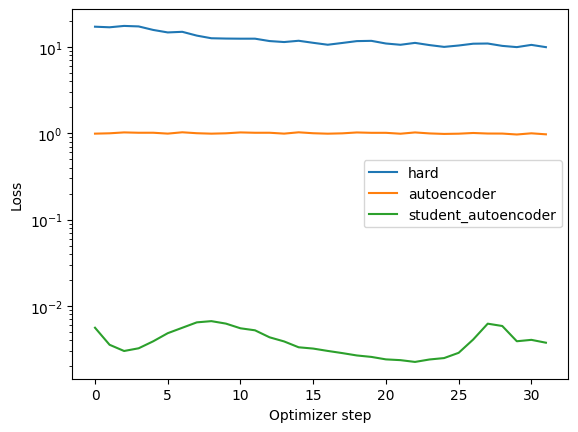

In [4]:
import matplotlib.pyplot as plt
for key in ('hard','autoencoder','student_autoencoder'):
    plt.plot([r['step'] for r in pilot['history']], [r[key] for r in pilot['history']], label=key)
plt.yscale('log'); plt.xlabel('Optimizer step'); plt.ylabel('Loss'); plt.legend(); plt.show()

The trace retains all 32 steps, including fluctuations, rather than presenting only favorable endpoints. It cannot establish anomaly discrimination or convergence.

## 14. Compute feasibility

The pilot step time can project an approximate 70,000-step paper-budget fit. Multiply by 45 for the requested all-category three-seed benchmark, then add data loading, evaluation and thermal margin. This extrapolation is not a measured full training runtime. Deterministic batch-one latency has a substantial p95 tail and needs further characterization.

In [5]:
seconds = pilot['seconds_per_step']
print({'estimated_70000_step_hours_per_model':seconds*70000/3600, 'estimated_45_model_training_hours':seconds*70000*45/3600, 'latency_ms':pilot['model_latency_ms']})

{'estimated_70000_step_hours_per_model': 3.048557664932458, 'estimated_45_model_training_hours': 137.18509492196063, 'latency_ms': {'p50': 33.47220001160167, 'p95': 145.27197999705095, 'warmup': 20, 'iterations': 100}}


At .1568 seconds per pilot step, linear projection is about 3.049 hours per 70k-step fit and 137.19 hours for 45 fits, excluding overhead. A full run is not yet validated; latency tails and sustained thermal behavior remain uncertain.

## 15. Bounded development plan

Proposed cap: 12 fits total, bottle and carpet, 2,000 steps each, seed 2026. Questions cover mean versus hard loss, AE contribution, map normalization, aggregation and capacity/budget. Penalty contrast requires legitimate documented external inputs and replaces another trial. No development fits have executed or been selected/rejected.

## 16. Model selection and calibration

Pending. No frozen final configuration or calibrated threshold exists. Later use development normals and fitting-derived synthetic proxies for selection, reserved calibration normals for strict score>threshold. Report sample size, nominal/observed FPR and uncertainty; no retrospective test tuning.

## 17. Frozen benchmark and metrics

Pending: zero final category-seed evaluations out of target 45. Image AUROC/AP, pixel AUROC/AP, AU-PRO, recall, FPR, precision and F1 are unavailable. No final metrics can be inferred from this normal-only pilot.

## 18. Failure analysis

Pending genuine test examples from all 15 categories after freeze. No false positive/negative claims are made. Later inspect scratches, textures, halos, logical/structural anomalies and localized responses missed by max aggregation alongside original images and masks; keep image panels local.

## 19. Six-model comparison

Pending EfficientAD evaluation. Previous Basic CNN, convolutional autoencoder, PatchCore, SuperSimpleNet Lite and PaDiM records remain unchanged. Later comparisons must match categories and report paired uncertainty, nine metrics, compute, memory and storage without unsupported superiority claims.

## 20. Validation, limitations and recovery

Focused core tests and deep pilot identity validation are provided. This notebook is a pilot-stage research record, not a completed milestone. No external penalty, only eight normals, fixed augmentation and 32 steps limit conclusions. Full development, calibration, benchmark, failure analysis and comparison remain. Notebook 07 is not started. Recovery instructions and current Git status are in docs/milestone_status.md.

### Development continuation — bounded study

The preceding 20 sections preserve the original pilot record and saved outputs. The following continuation supersedes its pending-development statements. It replays four newly executed fits and diagnostics; it does not launch training or final evaluation. The predeclared plan, fidelity audit and all successful or failed events are retained in the repository.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'reports').exists() else Path.cwd().parent
assert Path(sys.executable).resolve() == ROOT/'.venv/Scripts/python.exe'
D = ROOT/'reports/efficientad/development'
plan = json.loads((ROOT/'configs/efficientad_development.json').read_text())
results = [json.loads(p.read_text()) for p in sorted(D.glob('06-dev-*-v1.json'))]
selection = json.loads((D/'selection.json').read_text())
gate = json.loads((D/'feasibility.json').read_text())
latency = json.loads((D/'latency.json').read_text())
print({'replay': True, 'fits': len(results), 'steps': sum(r['steps'] for r in results), 'plan': plan})

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


{'replay': True, 'fits': 4, 'steps': 4116, 'plan': {'study_id': '06-development-v1', 'model_name': 'EfficientAD-S reduced-budget variant', 'categories': ['bottle', 'carpet'], 'seed': 2026, 'epoch_budgets': [3, 9], 'fresh_fits': 4, 'maximum_optimizer_steps': 4116, 'development_wall_time_cap_hours': 2, 'batch_size': 1, 'image_size': 256, 'precision': 'deterministic FP32; TF32 disabled', 'optimizer': {'name': 'Adam', 'learning_rate': 0.0001, 'weight_decay': 1e-05}, 'lr_policy': 'constant within each reduced budget', 'hard_quantile': 0.999, 'external_penalty': False, 'augmentation': 'one uniformly random brightness/contrast/saturation, coefficient U(0.8,1.2), tensor RGB before ImageNet normalization', 'teacher_sha256': 'b98a6a139087a0d743783ee59f367f0284af6003eb1a5fed0ce92bd9c0acd337', 'map_policy': 'development-normal q90/q99.5, resized maps, no clipping', 'candidate_scores': ['combined_max', 'local_max'], 'diagnostic_scores_only': ['global_max', 'raw_combined_max', 'combined_top1pct'], '

The plan was saved before training: bottle (147 fit normals) and carpet (196), fresh seed-2026 models at 3 and 9 epochs, 4,116 optimizer steps total. This supersedes the earlier proposed 12-fit study. Fixed epochs expose every fitting normal equally. No official test images, masks or scores were opened; test counts/dimensions come only from prior metadata for cost estimates.

### Reference fidelity and implementation

Read the complete audit below. The architecture remains the padded PDN-S teacher/student and 64x1x1-bottleneck autoencoder. The reduced epoch budget, omitted external-image penalty, constant short-run learning rate and tensor photometric augmentation are disclosed differences from the paper. Missing external penalty may let the student imitate teacher features beyond normals; the effect on real anomalies has not been measured.

In [2]:
print((ROOT/'docs/efficientad_fidelity_audit.md').read_text(encoding='utf-8'))
import inspect
import importlib.util
spec = importlib.util.spec_from_file_location('efficientad_development_driver', ROOT/'scripts/develop_efficientad.py')
driver = importlib.util.module_from_spec(spec)
spec.loader.exec_module(driver)
print(inspect.getsource(driver.fit))

# EfficientAD fidelity audit for bounded development

Reference: Batzner et al., WACV 2024, author's arXiv v3 reviewed in the pilot
phase; Algorithms 1/2 and architecture Tables 6/8. This audit inspects existing
`src/anomaly_detection/efficientad.py`; the architecture is not replaced.

| Component | Current implementation | Assessment |
|---|---|---|
| Teacher PDN-S | Four Conv2d layers, 128/256/256/384, 4/4/3/4 kernels, average pools, paper padding | Matches padded Table 6; 384x64x64 on 256 RGB |
| Teacher training status | `requires_grad_(False)`, `train()` override calls teacher.eval(), feature extraction under no_grad | Frozen; focused tests assert no teacher gradients |
| Teacher normalization | Channel population moments across fitting images and spatial positions, float64 accumulation | Full fitting partition for development, unlike eight-image pilot; variance floor 1e-12 is a numerical safeguard |
| Student | Same padded PDN, 768 output channels; first/last 384 heads | Matches 

def fit(category,epochs,rows,images,dev_rows,dev_images,plan):
    identifier=f'06-dev-{category}-e{epochs}-seed2026-v1'
    result_path=OUT/f'{identifier}.json'; checkpoint=CKPT/f'{identifier}.pt'
    if result_path.exists():
        result=json.loads(result_path.read_text())
        assert sha256(checkpoint)==result['checkpoint']['sha256']
        assert result['plan_sha256']==sha256(PLAN)
        assert (ROOT/f'experiments/{identifier}-result.json').exists()
        print('Reuse verified fit',identifier,flush=True)
        return result
    assert not (ROOT/f'experiments/{identifier}-start.json').exists(), 'Incomplete fit: inspect saved events/checkpoints before recovery'
    params=dict(categories=[category],epochs=epochs,steps=epochs*len(images),seed=2026,plan_sha256=sha256(PLAN))
    event(identifier+'-start','Full-epoch budget controls learning, normal score stability and paired synthetic discrimination',params)
    try:
        begin=time.perf_counter(); torch.manual_seed(2026)

The training code explicitly exposes shuffle order, random augmentation, hard loss, joint AE objectives, finite-gradient checks and complete-epoch timing. Teacher moments use every fitting normal and are cached by teacher/manifest/core identity for the second budget. Every completed fit has a checkpoint, map quantiles, exact replay check, result JSON, CSV diagnostics and append-only registry result. No existing pilot architecture was reimplemented.

### Latency diagnosis

Use the same saved pilot checkpoint for a controlled measurement audit: identical 1x3x256x256 FP32 input and unchanged model semantics. After 50 warmups per repeat, synchronize around 100 resident-input forwards in each of three repeats and record both wall and CUDA event time. Transfer and file-decode-through-CPU-map paths are timed separately. Events include stream launch gaps, so they are not a sum of isolated kernel durations.

{
  "methodology": "Same deterministic FP32 model, no semantic changes. 50 warmups/repeat, resident 1x3x256x256 input. Explicit synchronization and CUDA events; event time includes stream launch gaps. End-to-end includes file decode, CPU preprocessing, H2D, forward, D2H map and score.",
  "resident_wall": {
    "p50_ms": 41.98589999577962,
    "p95_ms": 54.11163998651319,
    "count": 300
  },
  "resident_gpu_event": {
    "p50_ms": 41.916303634643555,
    "p95_ms": 53.26419506072999,
    "count": 300
  },
  "per_repeat": [
    {
      "repeat": 0,
      "wall": {
        "p50_ms": 42.76404999836814,
        "p95_ms": 53.3351949925418,
        "count": 100
      },
      "gpu": {
        "p50_ms": 42.689537048339844,
        "p95_ms": 53.01920394897461,
        "count": 100
      }
    },
    {
      "repeat": 1,
      "wall": {
        "p50_ms": 41.30944999633357,
        "p95_ms": 56.56145499669947,
        "count": 100
      },
      "gpu": {
        "p50_ms": 41.23852729797363,
   

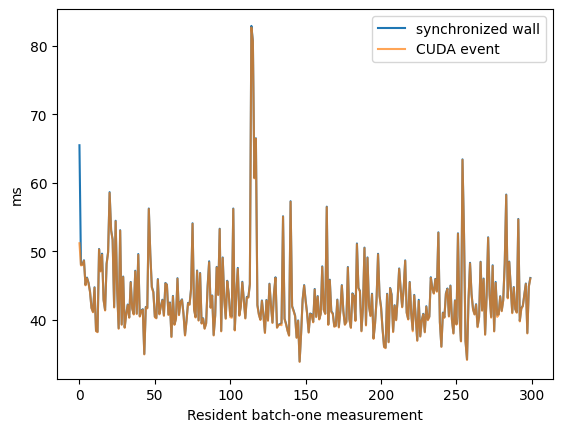

In [3]:
print(json.dumps({k:v for k,v in latency.items() if k not in ('samples','end_to_end_samples_ms','transfer_samples_ms')}, indent=2))
wall = np.array([r['wall_ms'] for r in latency['samples']])
events = np.array([r['gpu_ms'] for r in latency['samples']])
plt.plot(wall, label='synchronized wall'); plt.plot(events, label='CUDA event', alpha=.7)
plt.xlabel('Resident batch-one measurement'); plt.ylabel('ms'); plt.legend(); plt.show()

Resident wall p50/p95 = 41.99/54.11 ms, CUDA event = 41.92/53.26 ms (300 runs). End-to-end = 47.14/80.44 ms (100 runs); H2D = 0.274/0.402 ms. This run has a smaller p95 than the pilot, without a faster median. P0 and sampled clocks were stable; bursts did not remove the cost. CPU process usage near one core and modest GPU utilization are consistent with host/driver launch overhead. Windows scheduling remains a possible cause, not proven. No power/clock settings or score semantics were changed.

### Exploratory host-launch control, after selection

The initial audit motivates an execution-only CUDA graph control on the selected bottle checkpoint. It is run after the four fits and selection, and cannot influence model selection. Eager and graph execute the same full model, including both maps. Equality is checked before timing and on three additional normal inputs; capture failure is retained. Graph timing excludes capture and transfers and is not silently substituted into the final compute estimate.

In [4]:
control = json.loads((D/'launch-control.json').read_text())
print(json.dumps({k:v for k,v in control.items() if k not in ('eager','graph')},indent=2))
print({k:{m:v[m] for m in ('wall','gpu_event')} for k,v in control.items() if k in ('eager','graph')})

{
  "purpose": "Exploratory execution-only control after selection, no architecture/weight/score change. Graph replay is not silently adopted for final timing or feasibility.",
  "selected_checkpoint": {
    "experiment_id": "06-dev-bottle-e9-seed2026-v1",
    "plan_sha256": "f6953af23b5bee0564c9ca1010191885ffa549013bbcfbd429d163383e994d8e",
    "teacher_sha256": "b98a6a139087a0d743783ee59f367f0284af6003eb1a5fed0ce92bd9c0acd337",
    "epochs": 9,
    "category": "bottle",
    "seed": 2026,
    "final": false
  },
  "shape": [
    1,
    3,
    256,
    256
  ],
  "precision": "deterministic FP32",
  "warmup": 50,
  "repeats": 3,
  "iterations_per_repeat": 100,
  "graph_max_abs_error": [
    0.0,
    0.0
  ],
  "graph_bitwise_equal": true,
  "additional_input_max_abs_errors": [
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0
  ],
  "graph_status": "measured",
  "profiler_table": "-------------------------------------------------------  ------------  ------------  ------------  ----

The paired eager wall p50/p95 is 25.98/32.23 ms; fixed-shape graph replay is 19.26/19.63 ms (300 each). Graph capture, image transfer and preprocessing are excluded. A lower graph time supports host-dispatch overhead as a contributor, without identifying a specific Windows scheduling mechanism. All subsequent feasibility arithmetic conservatively retains eager timing. This exploratory control changes execution scheduling, not architecture, weights or anomaly-score definitions.

### Full-epoch learning curves

Every plotted point below is a recorded full epoch. Training means include hard-feature, autoencoder and student-autoencoder loss; held-out normal maxima track unnormalized score drift without repeatedly refitting maps. A falling loss is necessary but does not establish anomaly sensitivity. Fixed fitting probes before/after also separate training-mode dropout fluctuations from actual learning.

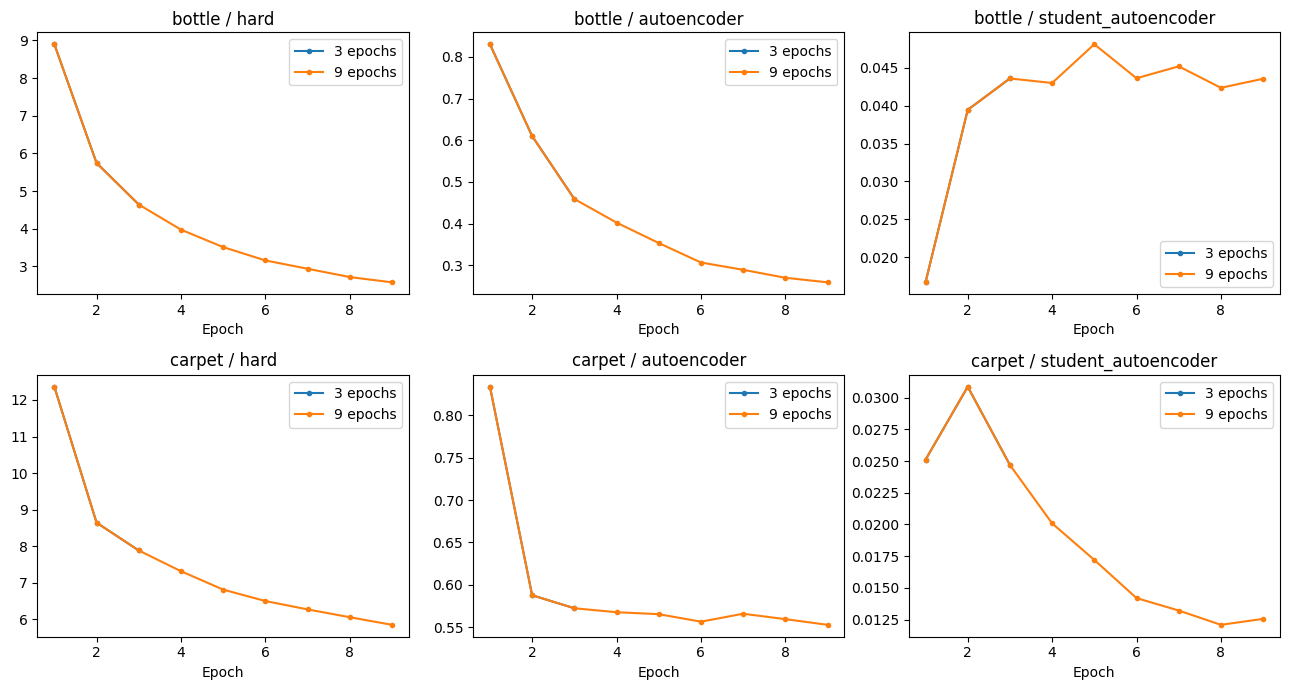

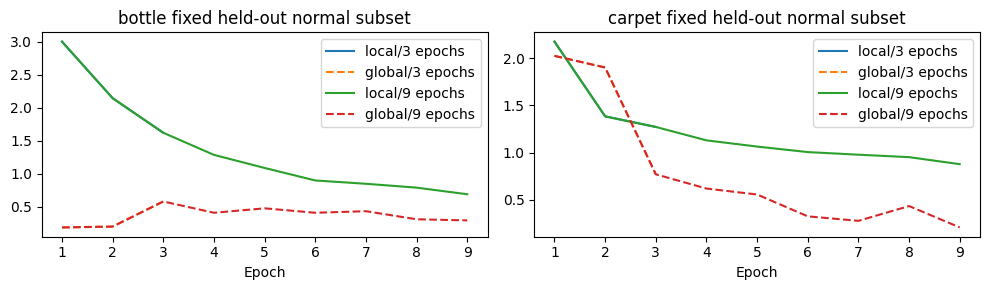

category  epochs  steps  train_seconds  hard_before  hard_after  ae_before  ae_after                                                                                                                                         development_probe
  bottle       3    441      65.620688    17.999707    4.273714   1.003767  0.426524   {'hard': 4.18828159570694, 'penalty': 0.0, 'autoencoder': 0.41827185451984406, 'student_autoencoder': 0.02890788810327649, 'total': 4.6354615688323975}
  bottle       9   1323     185.597321    17.999707    2.399083   1.003767  0.230009 {'hard': 2.379307448863983, 'penalty': 0.0, 'autoencoder': 0.22196530550718307, 'student_autoencoder': 0.021848079282790422, 'total': 2.6231207847595215}
  carpet       3    588      65.866850    21.076909    8.210890   1.088874  0.612716  {'hard': 9.347878456115723, 'penalty': 0.0, 'autoencoder': 0.6544092148542404, 'student_autoencoder': 0.015717095928266644, 'total': 10.018004894256592}
  carpet       9   1764     226.663999    21

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13,7))
for i, category in enumerate(plan['categories']):
    for r in results:
        if r['category'] != category: continue
        curves = pd.DataFrame(r['curves'])
        for j,key in enumerate(('hard','autoencoder','student_autoencoder')):
            axes[i,j].plot(curves.epoch, curves[key], marker='.', label=f"{r['epochs']} epochs")
            axes[i,j].set_title(category+' / '+key); axes[i,j].set_xlabel('Epoch'); axes[i,j].legend()
fig.tight_layout(); plt.show()
fig, axes = plt.subplots(1,2,figsize=(10,3))
for ax,category in zip(axes,plan['categories']):
    for r in results:
        if r['category'] != category: continue
        curves = pd.DataFrame(r['curves'])
        ax.plot(curves.epoch,curves.raw_local_dev_max_median,label=f"local/{r['epochs']} epochs")
        ax.plot(curves.epoch,curves.raw_global_dev_max_median,linestyle='--',label=f"global/{r['epochs']} epochs")
    ax.set_title(category+' fixed held-out normal subset'); ax.set_xlabel('Epoch'); ax.legend()
fig.tight_layout(); plt.show()
print(pd.DataFrame([dict(category=r['category'],epochs=r['epochs'],steps=r['steps'],train_seconds=r['training_seconds'],hard_before=r['probe_before']['hard'],hard_after=r['probe_after']['hard'],ae_before=r['probe_before']['autoencoder'],ae_after=r['probe_after']['autoencoder'],development_probe=r['development_probe_losses']) for r in results]).to_string(index=False))

All meaningful epoch fluctuations are retained. Compare the fixed-probe endpoints and held-out development score drift with the synthetic discrimination table below. Different score scales across budgets are expected before development-map normalization; they do not by themselves imply worsening normal false alarms. This study has one development seed and cannot establish across-seed stability.

### Proxy discrimination and autoencoder contribution

For 16 fitting normals per category, deterministic scratch, block and color edits yield 48 synthetic anomalous images. Their backgrounds participated in fitting, so results are optimistic proxies rather than real-defect generalization. Report each edit and paired score change. Combined versus local-only is an inference map ablation with identical trained weights; global-only, raw-map and top-1%-mean are diagnostic scores, not extra selected trials.

In [6]:
rows = []
for r in results:
    for score,v in r['proxy'].items():
        rows.append(dict(category=r['category'],epochs=r['epochs'],score=score,proxy_auroc=v['auroc'],proxy_ap=v['ap'],scratch=v['per_edit']['scratch'],block=v['per_edit']['block'],color_patch=v['per_edit']['color_patch'],paired_delta=v['mean_paired_score_delta']))
print(pd.DataFrame(rows).to_string(index=False))
print('Development-normal score distributions and leave-one-image-out map-scaling ranges:')
for r in results:
    print(r['experiment_id'], r['development_score_distributions'], r['leave_one_development_image_out_quantile_range'])
print('Across-budget normal score rank correlations:')
from scipy.stats import spearmanr
for category in plan['categories']:
    tables = [pd.read_csv(D/f"06-dev-{category}-e{e}-seed2026-v1-development.csv").set_index('path') for e in plan['epoch_budgets']]
    print(category, {s: float(spearmanr(tables[0][s],tables[1].loc[tables[0].index,s]).statistic) for s in plan['candidate_scores']})

category  epochs            score  proxy_auroc  proxy_ap  scratch    block  color_patch                                                                                            paired_delta
  bottle       3     combined_max     0.674479  0.895321 0.687500 0.335938     1.000000    {'scratch': 0.07549706101417542, 'block': -0.0016382485628128052, 'color_patch': 31.136669158935547}
  bottle       3        local_max     0.878255  0.942708 0.833984 0.800781     1.000000        {'scratch': 0.2643268406391144, 'block': 0.07223925739526749, 'color_patch': 20.223596572875977}
  bottle       3       global_max     0.592448  0.853732 0.441406 0.335938     1.000000  {'scratch': -0.0008839331567287445, 'block': -0.0032765045762062073, 'color_patch': 42.11472702026367}
  bottle       3 raw_combined_max     0.701823  0.906778 0.722656 0.382812     1.000000      {'scratch': 0.24004849791526794, 'block': 0.0009313970804214478, 'color_patch': 39.74135971069336}
  bottle       3 combined_top1pct     0.

C:\Users\shaik\AppData\Local\Temp\ipykernel_23484\3716876864.py:13: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  print(category, {s: float(spearmanr(tables[0][s],tables[1].loc[tables[0].index,s]).statistic) for s in plan['candidate_scores']})


The sensitivity varies by edit and category; none of these scores is official-test AUROC. Proxy AP has a .75 random-ranking reference because 48 of 64 proxy-panel images are edited, and edits share only 16 backgrounds. Normal development distributions and leave-one-out map quantiles expose scaling instability without using reserved calibration for selection. Rejected score diagnostics remain in every CSV. Structural/logical anomalies and fine real scratches remain untested. See the selection table for the predeclared decision rather than choosing the best individual edit retrospectively.

### Configuration selection, locked before calibration

Eligibility requires finite losses/gradients/maps, lower fitting-probe hard and AE losses, and proxy AUROC at least .65 in each category. Rank macro proxy AUROC; select three epochs if within .02 of the best eligible nine-epoch candidate, and prefer combined-max within .02 of local-max. The selection JSON was written before opening reserved calibration images.

In [7]:
print(json.dumps(selection, indent=2))
print('Candidate decisions:')
print(pd.DataFrame(selection['candidates']).to_string(index=False))

{
  "eligible": true,
  "candidates": [
    {
      "epochs": 3,
      "score": "combined_max",
      "eligible": true,
      "macro_proxy_auroc": 0.7936197916666666,
      "worst_category_proxy_auroc": 0.6744791666666666
    },
    {
      "epochs": 3,
      "score": "local_max",
      "eligible": true,
      "macro_proxy_auroc": 0.9287109375000001,
      "worst_category_proxy_auroc": 0.8782552083333335
    },
    {
      "epochs": 9,
      "score": "combined_max",
      "eligible": true,
      "macro_proxy_auroc": 0.97265625,
      "worst_category_proxy_auroc": 0.9466145833333333
    },
    {
      "epochs": 9,
      "score": "local_max",
      "eligible": true,
      "macro_proxy_auroc": 0.9947916666666666,
      "worst_category_proxy_auroc": 0.9908854166666666
    }
  ],
  "selected": {
    "epochs": 9,
    "score": "local_max",
    "eligible": true,
    "macro_proxy_auroc": 0.9947916666666666,
    "worst_category_proxy_auroc": 0.9908854166666666
  },
  "plan_sha256": "f6953af23b5b

Selected **9 epochs, local_max**, eligibility=True, macro proxy AUROC=0.9948. This is the predeclared decision, not a paper-equivalence claim. The exact .65/.02 criteria and both rejected budgets/scores remain visible. Calibration results below do not alter this selection. The reduced configuration is named EfficientAD-S reduced-budget variant.

### Reserved-normal calibration feasibility

After the selection lock, use all reserved clean calibration normals: 31 bottle and 42 carpet. Freeze nominal 5% FPR, higher 95th percentile, strict score>threshold. Bootstrap 1,000 times and delete one sample at a time to expose threshold sensitivity. Also report the continuous-IID order-statistic future-FPR interval. A binomial interval on reused calibration exceedances is descriptive, not coverage for a fitted threshold.

[
  {
    "threshold": 0.5066908597946167,
    "nominal_fpr": 0.05,
    "strict_greater": true,
    "quantile_method": "higher",
    "calibration_distribution": {
      "n": 31,
      "min": 0.5066908597946167,
      "median": 0.5066908597946167,
      "mean": 0.5066908597946167,
      "std": 0.0,
      "q90": 0.5066908597946167,
      "q95": 0.5066908597946167,
      "max": 0.5066908597946167
    },
    "observed_calibration_fpr": 0.0,
    "exceedances": 0,
    "calibration_exceedance_descriptive_cp95": [
      0.0,
      0.11218874692236996
    ],
    "uncertainty_note": "Tied calibration scores violate the continuous-score assumption: Beta future-FPR interval is not asserted. The retained hypothetical interval is reference only; degenerate bootstrap tails do not establish certainty. CP calibration interval is descriptive because threshold was fitted on those samples.",
    "bootstrap_threshold_p025_p50_p975": [
      0.5066908597946167,
      0.5066908597946167,
      0.506690859794

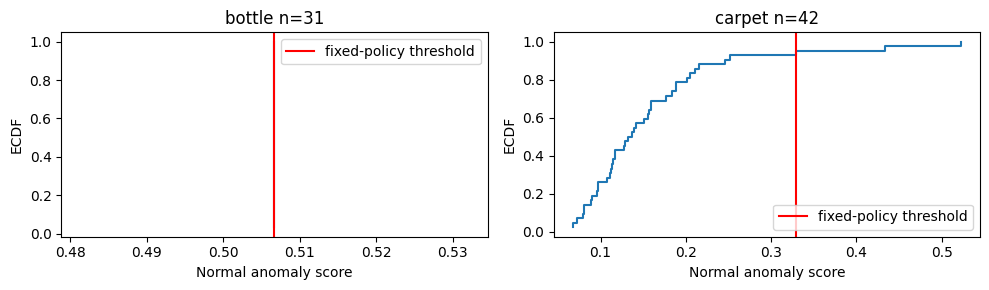

In [8]:
calibration = [json.loads((D/f'calibration-{c}-corrected.json').read_text()) for c in plan['categories']]
print(json.dumps(calibration,indent=2))
print('Precision audit:',json.loads((D/'calibration-precision-audit.json').read_text()))
fig, axes = plt.subplots(1,2,figsize=(10,3))
for ax,c in zip(axes,calibration):
    table=pd.read_csv(D/f"{c['category']}-calibration-exact-scores.csv",float_precision='round_trip')
    values=np.sort(table.score)
    ax.step(values,np.arange(1,len(values)+1)/len(values),where='post')
    ax.axvline(c['threshold'],color='red',label='fixed-policy threshold')
    ax.set_title(c['category']+f" n={len(values)}"); ax.set_xlabel('Normal anomaly score'); ax.set_ylabel('ECDF'); ax.legend()
fig.tight_layout(); plt.show()

The precision audit repairs an evaluation serialization error: rounded float32 decimal values read as float64 inflated bottle development exceedances. Original reports are preserved; exact values are now promoted before export and parsed with round-trip precision. No training, score definition, threshold or model selection changed. Bottle has one unique calibration score across 31 normals; its identical maximum is a score floor, while spatial maps still vary. The zero-width bootstrap range is not certainty; the continuous-score Beta interval is inapplicable and explicitly null. Carpet retains a wide bootstrap range. The smaller all-category calibration partitions (for example toothbrush n=9) will be still less precise. No calibration observations select a different setting or justify a post-test adjustment.

### Measured compute and 45-model feasibility

Use complete-epoch timings from both categories, retaining the slower selected-budget seconds/image. Add measured full-fitting normalization/preparation, normal map scaling, calibration, decode-through-CPU-map inference, checkpoint serialization/reload, synthetic native-metric N log N cost, and 60 seconds/model fixed CPU artifact/validation overhead. Multiply the entire sequential elapsed estimate by two. Test counts and dimensions are metadata-only; no test pixels or masks were accessed.

In [9]:
print(pd.DataFrame([dict(category=r['category'],epochs=r['epochs'],train_s=r['training_seconds'],seconds_per_image_epoch=r['seconds_per_image_epoch'],prep_s=r['preparation_seconds'],diagnostics_s=r['diagnostic_seconds'],serialization_validation_s=r['serialization_validation_seconds'],ram_bytes=r['process_peak_working_set_bytes'],gpu_allocated_bytes=r['peak_gpu_allocated_bytes'],gpu_reserved_bytes=r['peak_gpu_reserved_bytes']) for r in results]).to_string(index=False))
print(json.dumps({k:v for k,v in gate.items() if k!='workload'},indent=2))
print(pd.DataFrame([dict(category=r['category'],**r['per_model_seconds'],three_seed_conservative_hours=r['conservative_three_seed_seconds']/3600) for r in gate['workload']]).to_string(index=False))

category  epochs    train_s  seconds_per_image_epoch   prep_s  diagnostics_s  serialization_validation_s  ram_bytes  gpu_allocated_bytes  gpu_reserved_bytes
  bottle       3  65.620688                 0.148800 1.441082      62.731987                    0.638044 1973071872            329485312           455081984
  bottle       9 185.597321                 0.140285 0.149494      33.753909                    0.621206 1974784000            329565184           455081984
  carpet       3  65.866850                 0.112018 1.708653      63.792810                    0.551636 2111066112            329565184           455081984
  carpet       9 226.663999                 0.128494 0.098296      67.662803                    0.566080 2111066112            329565184           455081984
{
  "recommendation": "GO",
  "target_hours": 12,
  "estimated_conservative_total_elapsed_hours": 10.158889779561685,
  "estimated_training_hours_no_margin": 2.684006603460687,
  "models": 45,
  "categories": 15,
  

The conservative estimate is **10.16 hours for 45 models**, including CPU work and a factor-two margin; raw projected training is 2.68 hours. Recommendation: **GO** against the 12-hour target. This is a cost forecast, not measured final GPU-hours; sustained thermals, other categories and exact native metric workloads may differ. All 15 categories and seeds 2026/2027/2028 remain planned. No final model has been trained by this phase.

### Development conclusion and remaining milestone work

Four fits and their complete learning histories, latency audit, fidelity audit, calibration sensitivity and feasibility arithmetic are retained. Teacher provenance and separate checkpoint-license uncertainty remain unchanged. Missing penalty, short training, one development seed, optimistic proxies and small calibration tails limit the evidence. Final nine metrics, real category-specific failures and six-model comparison remain unavailable until a frozen benchmark. Notebook 07 remains unstarted. Validation and recovery evidence live in docs/milestone_status.md and reports/efficientad/development/validation.json.